# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge.

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms.

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY).

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS:
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [2]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz
!wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz
!gunzip SUSY.csv.gz

--2026-10-24 04:19:05--  http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘SUSY.csv.gz’

SUSY.csv.gz             [           <=>      ] 879.65M  5.18MB/s    in 2m 57s  

2026-10-24 04:22:03 (4.96 MB/s) - ‘SUSY.csv.gz’ saved [922377711]



In [ ]:
#!rm SUSY.csv

In [ ]:
#!gunzip SUSY.csv.gz

In [3]:
ls -lh

total 2.3G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root 2.3G Oct 24 04:22 SUSY.csv


The data is provided as a comma separated file.

In [4]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [5]:
!ls -lh

total 2.3G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data
-rw-r--r-- 1 root root 2.3G Oct 24 04:22 SUSY.csv


We see that we have 5 million datapoints.

In [6]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [7]:
!head -500000 SUSY.csv > SUSY-small.csv

In [8]:
ls -lh

total 2.5G
drwxr-xr-x 1 root root 4.0K Oct 21 13:23 sample_data/
-rw-r--r-- 1 root root 2.3G Oct 24 04:22 SUSY.csv
-rw-r--r-- 1 root root 228M Oct 24 04:22 SUSY-small.csv


In [9]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [10]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [11]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [12]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [13]:
FeatureNames

['cos_theta_r1',
 'MT2',
 'S_R',
 'M_TR_2',
 'axial_MET',
 'R',
 'dPhi_r_b',
 'M_Delta_R',
 'M_R',
 'MET_rel']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [15]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [16]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [17]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


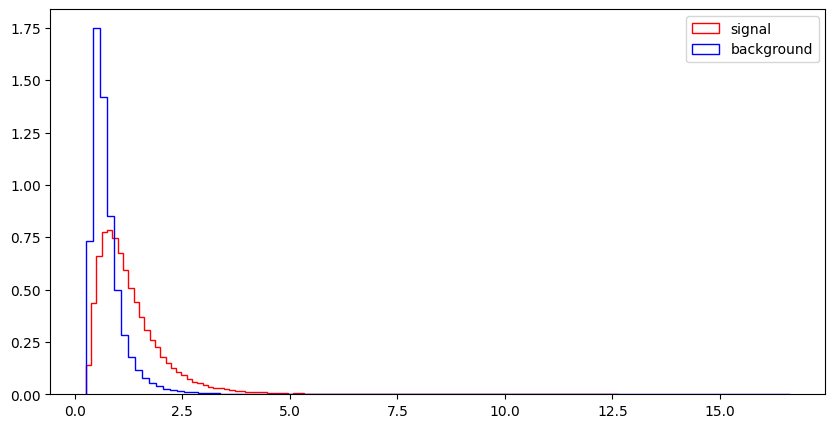

l_1_eta


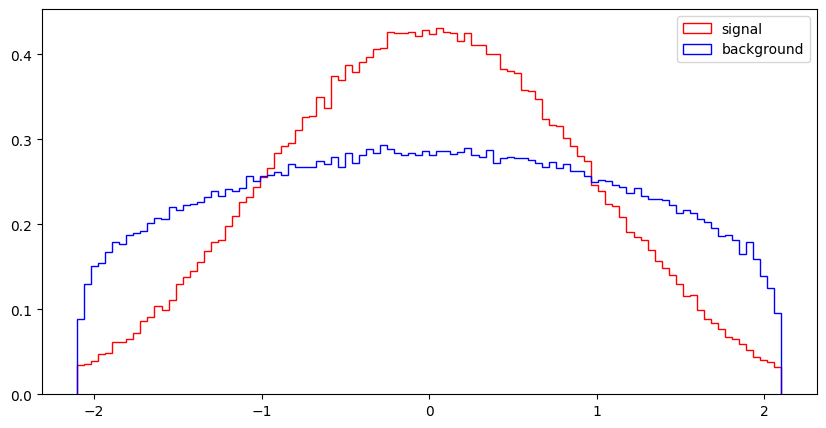

l_1_phi


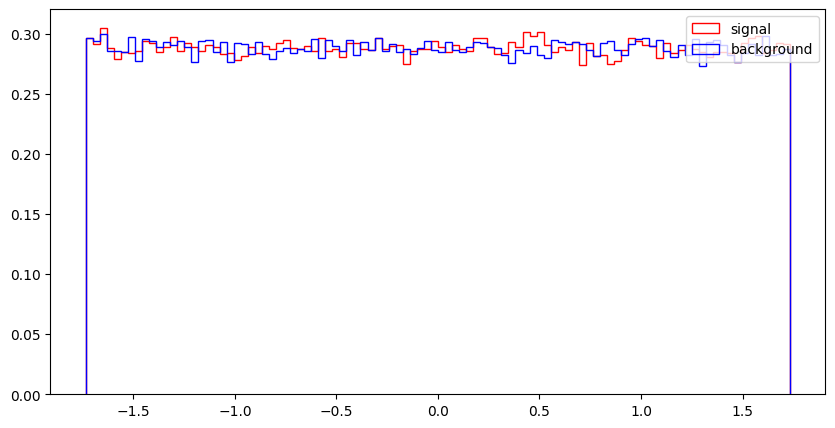

l_2_pT


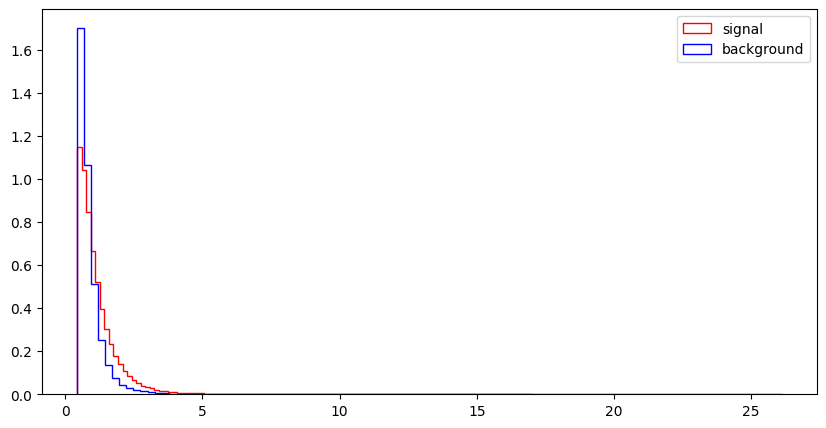

l_2_eta


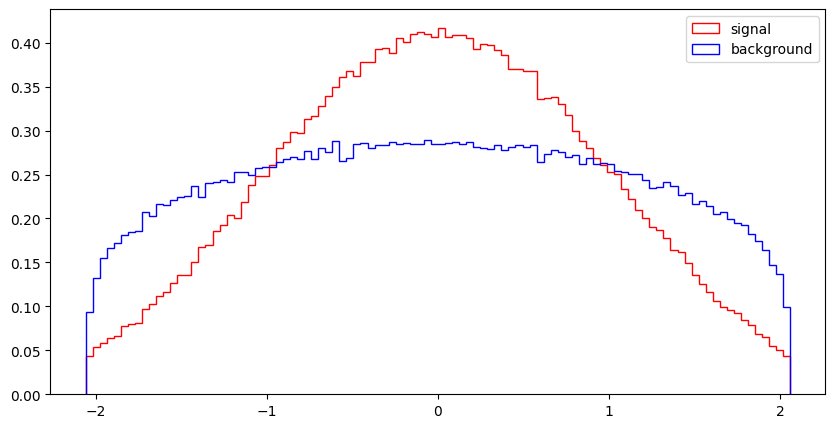

l_2_phi


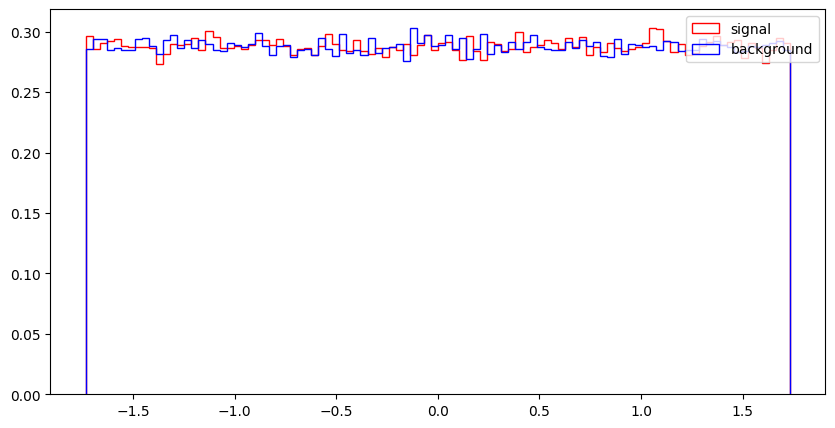

MET


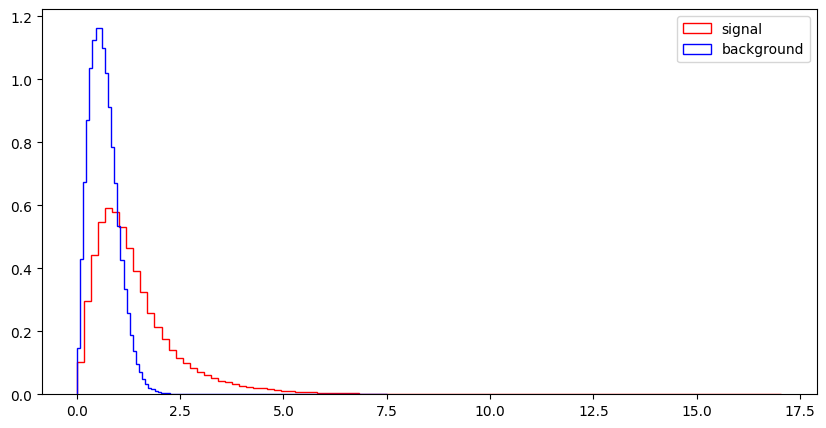

MET_phi


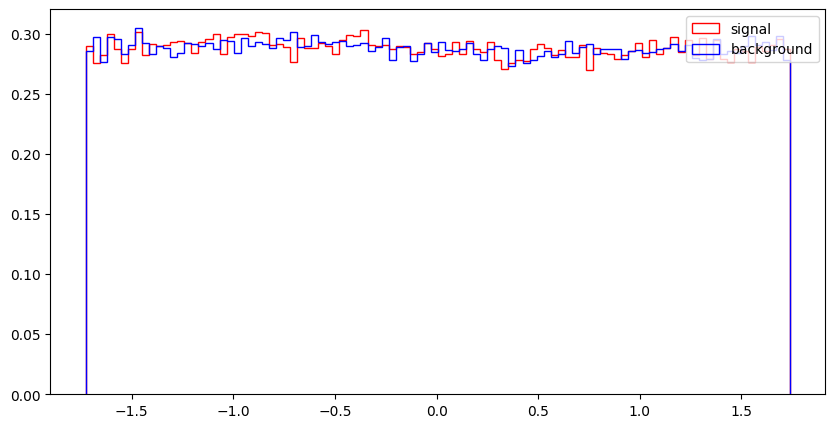

MET_rel


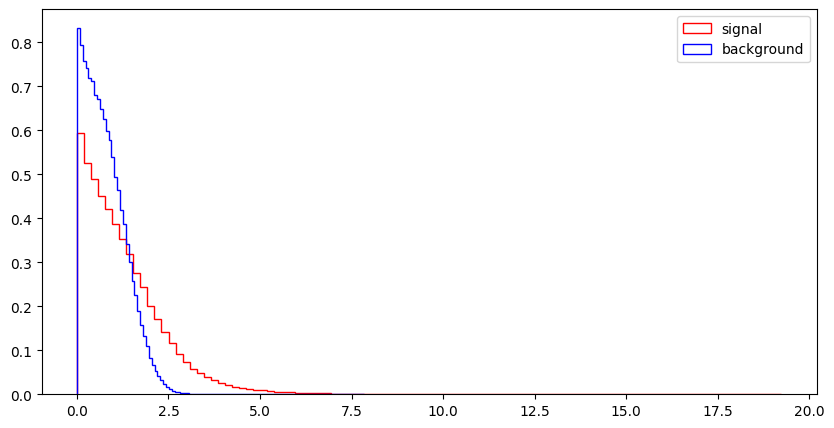

axial_MET


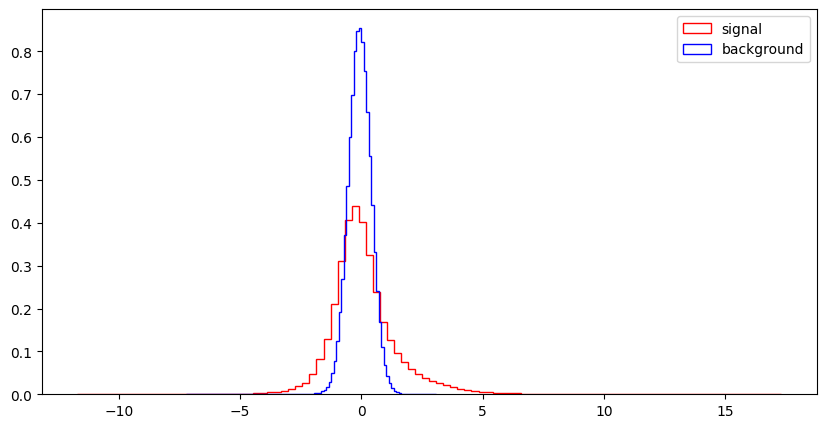

M_R


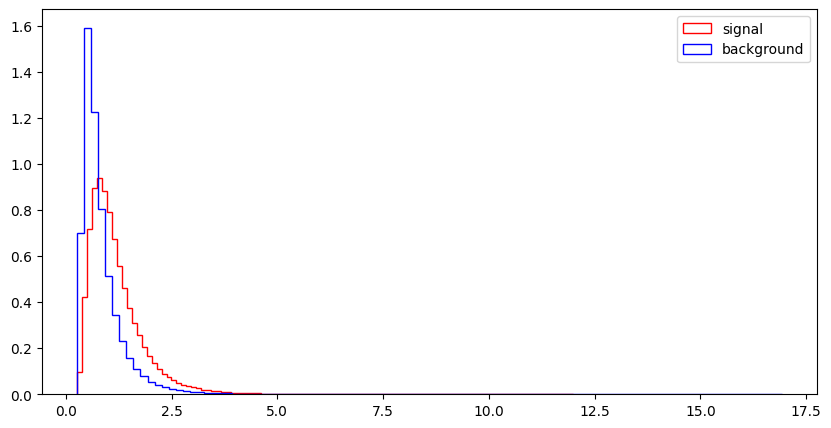

M_TR_2


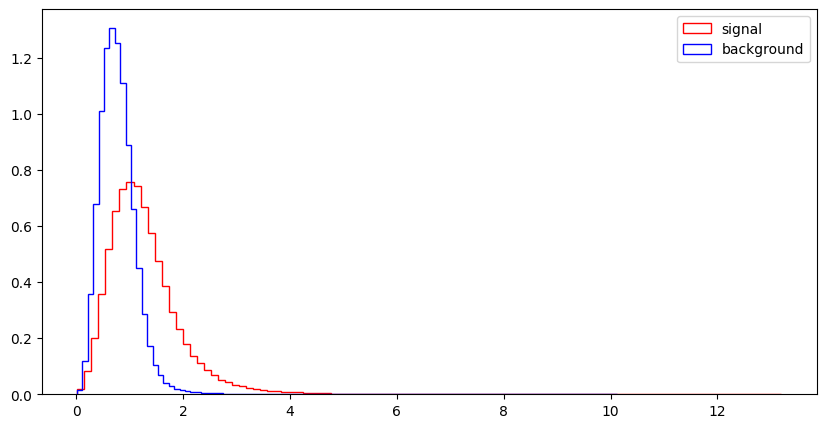

R


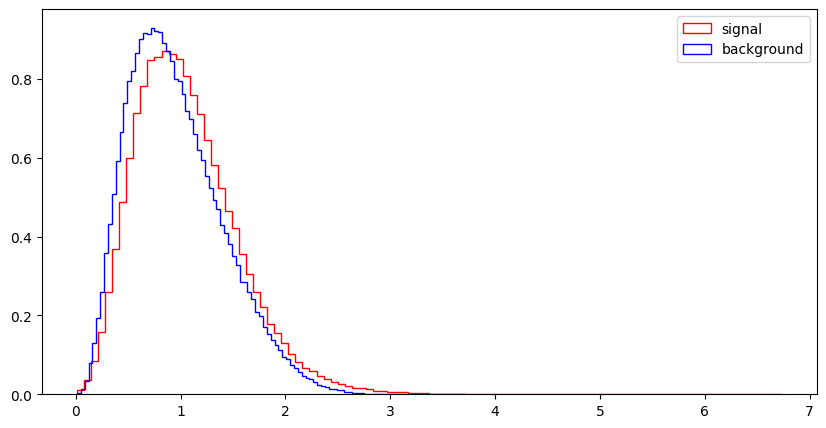

MT2


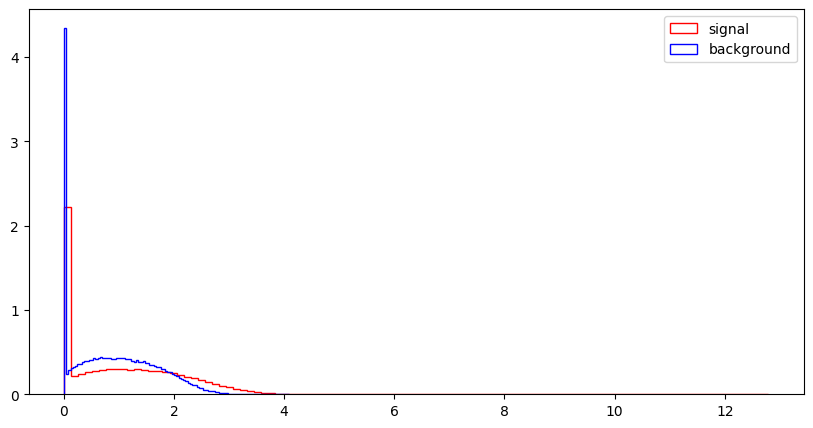

S_R


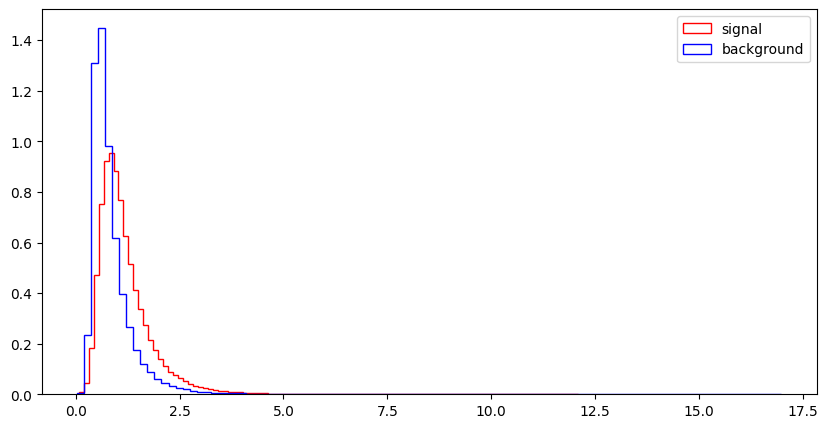

M_Delta_R


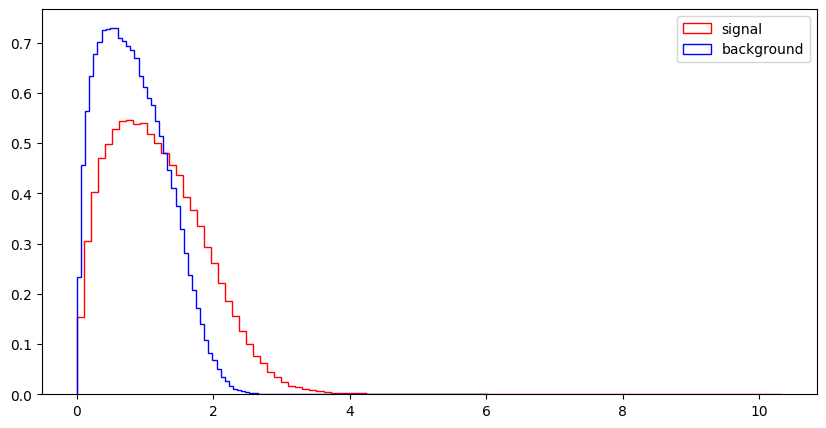

dPhi_r_b


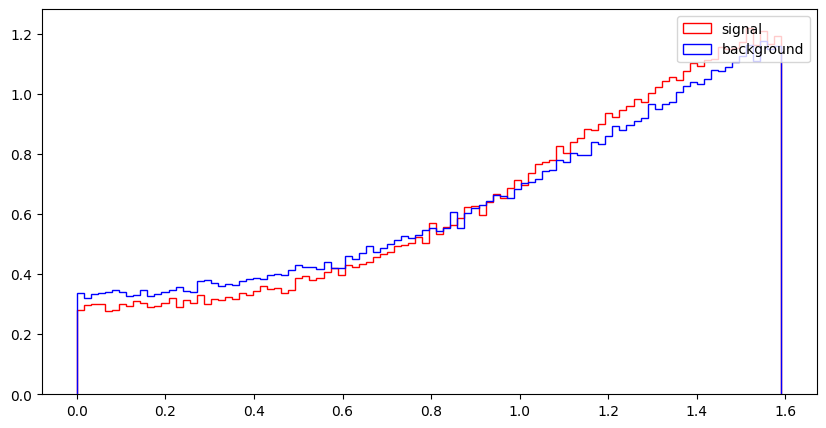

cos_theta_r1


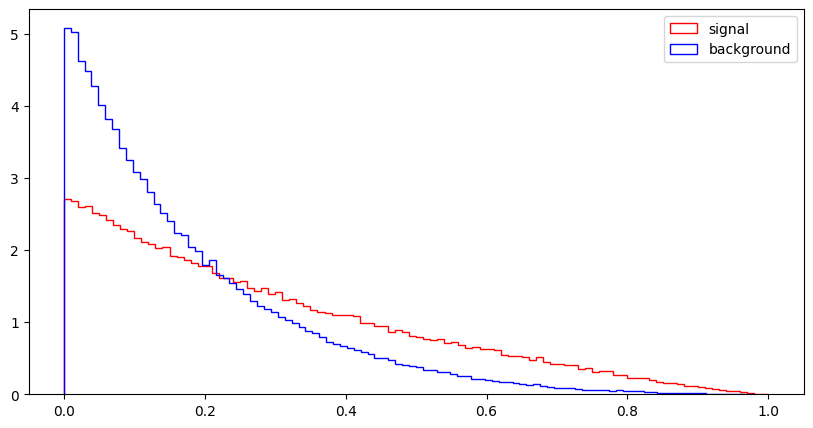

In [18]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

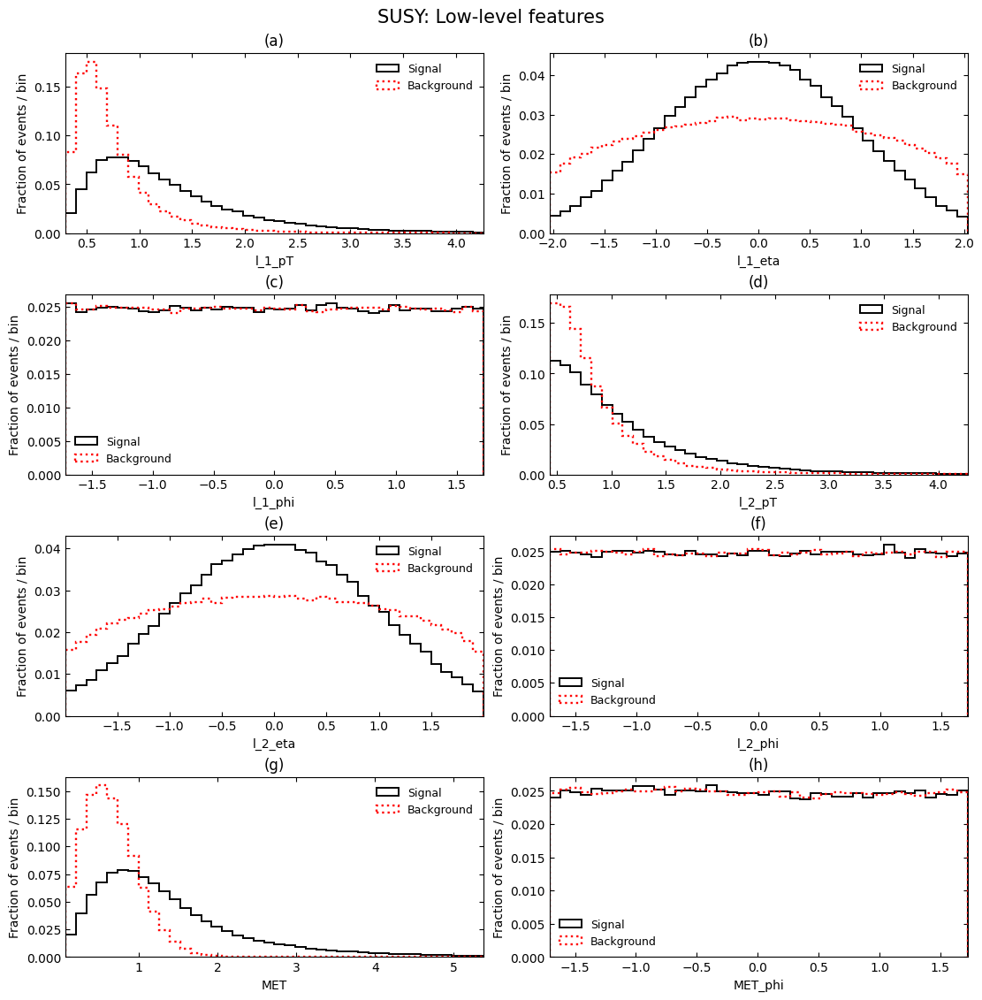

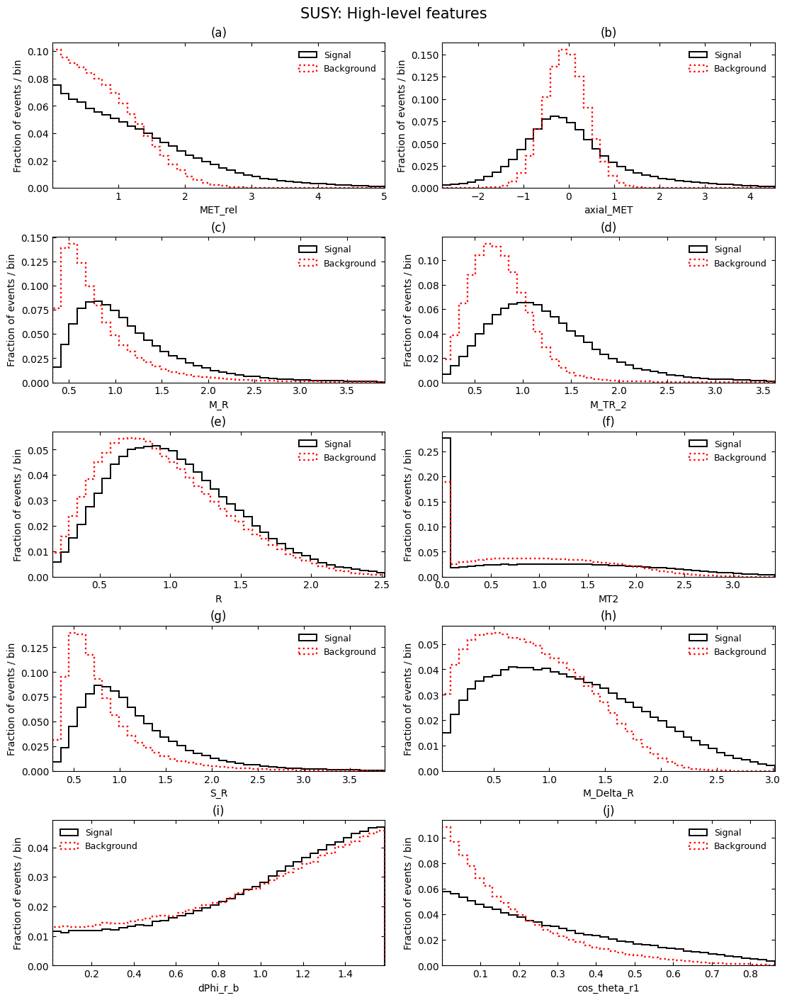

In [19]:
FeatureNames = [v for v in VarNames[1:] if v not in RawNames]

def plot_distributions(variables, title):
    nrows = (len(variables) + 1) // 2

    fig, axes = plt.subplots(
        nrows, 2,
        figsize=(11, 2.8 * nrows),
        constrained_layout=True
    )

    for i, (ax, var) in enumerate(zip(axes.flat, variables)):
        signal = df_sig[var].to_numpy()
        background = df_bkg[var].to_numpy()

        # Displaying the central 99% using shared bins.
        lo, hi = np.quantile(df[var], [0.005, 0.995])
        bins = np.linspace(lo, hi, 41)

        ax.hist(
            signal, bins=bins,
            weights=np.ones(len(signal)) / len(signal),
            histtype="step", color="black",
            linewidth=1.4, label="Signal"
        )

        ax.hist(
            background, bins=bins,
            weights=np.ones(len(background)) / len(background),
            histtype="step", color="red",
            linestyle=":", linewidth=1.7,
            label="Background"
        )

        ax.set_xlabel(var)
        ax.set_ylabel("Fraction of events / bin")
        ax.set_xlim(lo, hi)
        ax.set_ylim(bottom=0)
        ax.set_title(f"({chr(97 + i)})")
        ax.tick_params(direction="in", top=True, right=True)
        ax.legend(frameon=False, fontsize=9)

    for ax in list(axes.flat)[len(variables):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=15)
    plt.show()

plot_distributions(RawNames, "SUSY: Low-level features")
plot_distributions(FeatureNames, "SUSY: High-level features")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

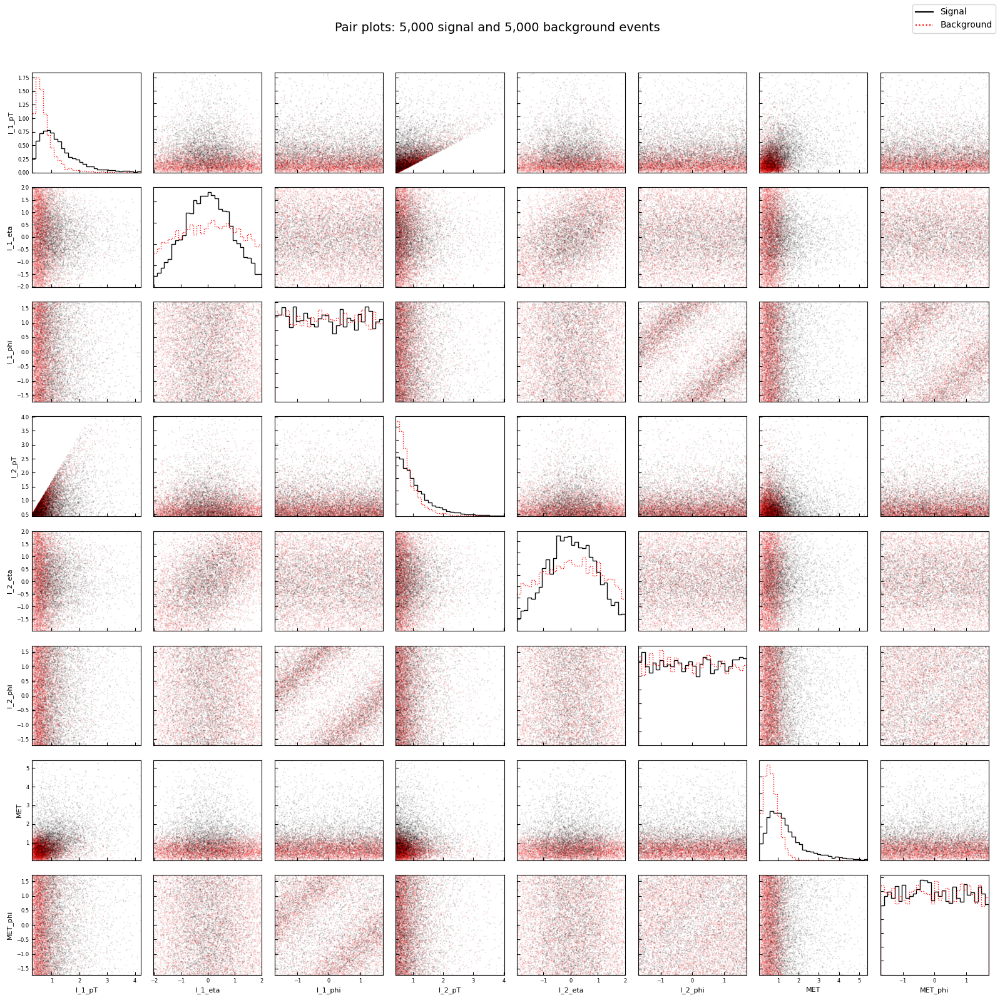

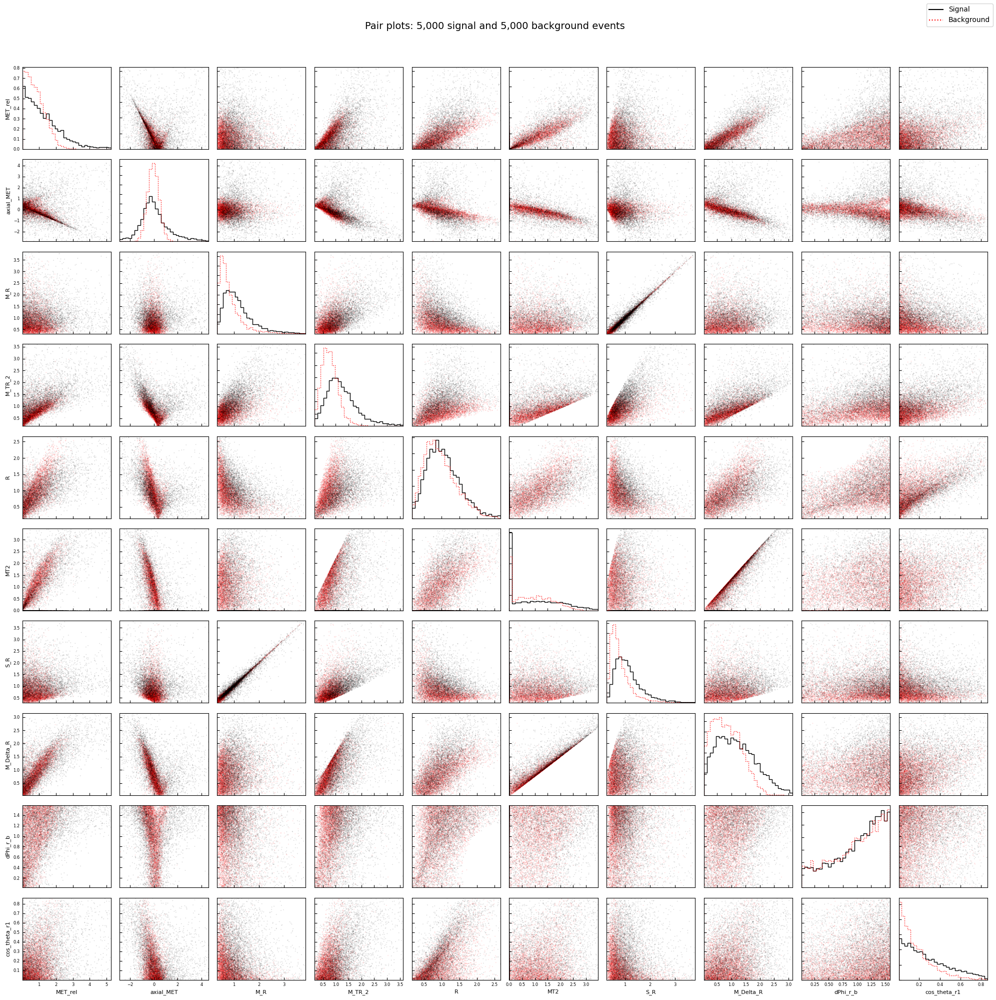

In [20]:
#a
from matplotlib.lines import Line2D

def pair_plots(data, variables, n_per_class=5000, seed=42):
    signal = data.loc[data["signal"] == 1, variables]
    background = data.loc[data["signal"] == 0, variables]

    # Sample for plotting speed.
    if n_per_class is not None:
        signal = signal.sample(
            n=min(n_per_class, len(signal)), random_state=seed
        )
        background = background.sample(
            n=min(n_per_class, len(background)), random_state=seed
        )

    sig = signal.to_numpy()
    bkg = background.to_numpy()

    n = len(variables)
    fig, axes = plt.subplots(
        n, n, figsize=(2 * n, 2 * n), squeeze=False
    )

    limits = [
        np.quantile(
            np.concatenate([sig[:, j], bkg[:, j]]),
            [0.005, 0.995]
        )
        for j in range(n)
    ]

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]

            if i == j:
                bins = np.linspace(*limits[j], 31)

                ax.hist(
                    sig[:, j], bins=bins, density=True,
                    histtype="step", color="black"
                )
                ax.hist(
                    bkg[:, j], bins=bins, density=True,
                    histtype="step", color="red",
                    linestyle=":"
                )

            else:
                ax.scatter(
                    bkg[:, j], bkg[:, i],
                    s=2, alpha=0.12, color="red",
                    edgecolors="none", rasterized=True
                )
                ax.scatter(
                    sig[:, j], sig[:, i],
                    s=2, alpha=0.12, color="black",
                    edgecolors="none", rasterized=True
                )
                ax.set_ylim(*limits[i])

            ax.set_xlim(*limits[j])
            ax.tick_params(labelsize=6, direction="in")

            if i == n - 1:
                ax.set_xlabel(variables[j], fontsize=8)
            else:
                ax.tick_params(labelbottom=False)

            if j == 0:
                ax.set_ylabel(variables[i], fontsize=8)
            else:
                ax.tick_params(labelleft=False)

    handles = [
        Line2D([0], [0], color="black", label="Signal"),
        Line2D(
            [0], [0], color="red",
            linestyle=":", label="Background"
        )
    ]

    fig.legend(handles=handles, loc="upper right")
    fig.suptitle(
        f"Pair plots: {len(sig):,} signal and "
        f"{len(bkg):,} background events",
        fontsize=14
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

pair_plots(df, RawNames)
pair_plots(df, FeatureNames)

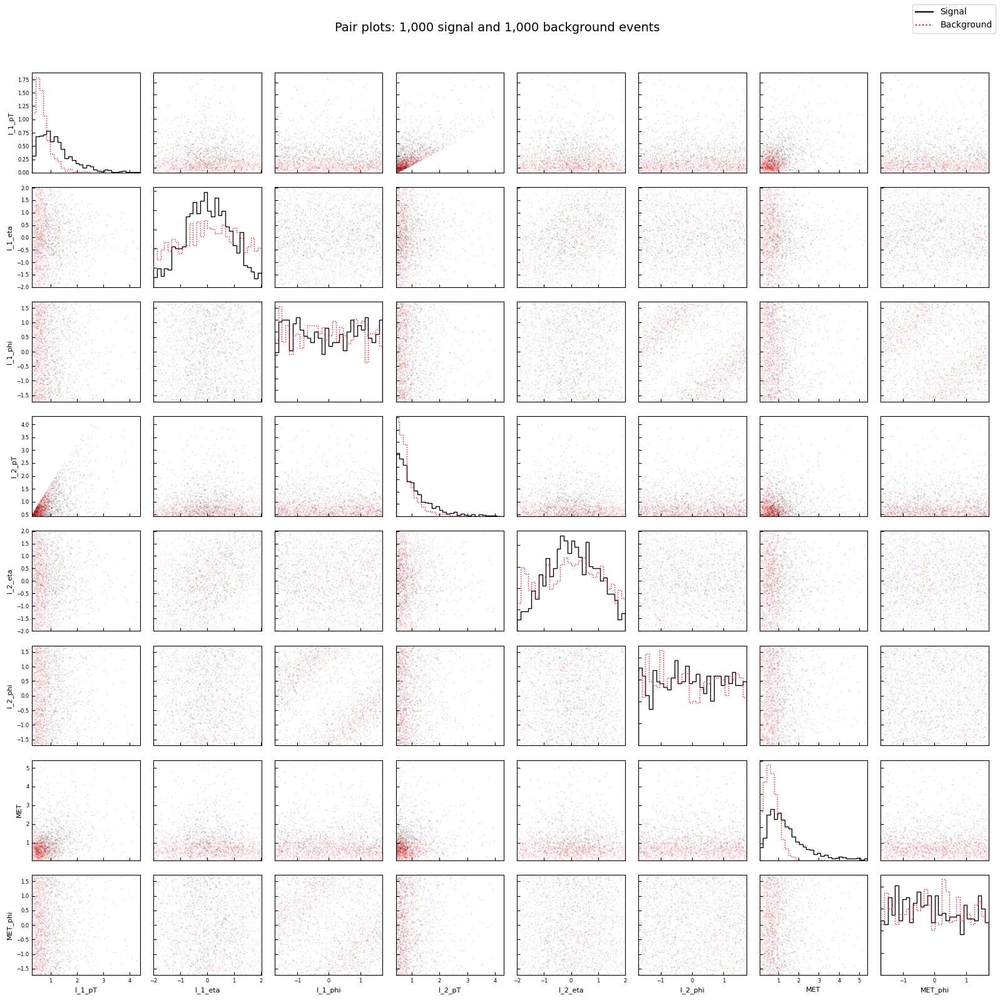

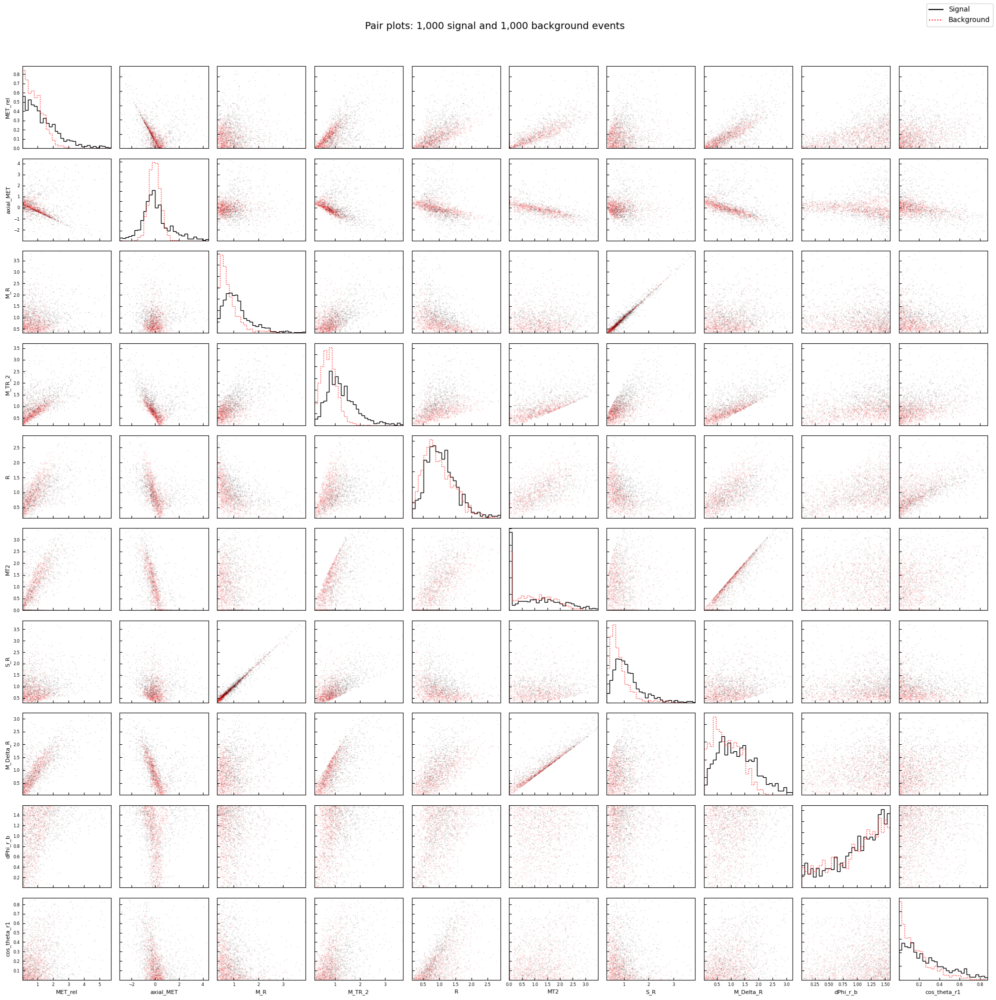

In [21]:
#b
pair_plots(df, RawNames, n_per_class=1000)
pair_plots(df, FeatureNames, n_per_class=1000)

In [22]:
#c

separation = {}

for var in VarNames[1:]:
    bins = np.unique(
        np.quantile(df[var], np.linspace(0, 1, 51))
    )

    signal_counts, _ = np.histogram(df_sig[var], bins=bins)
    background_counts, _ = np.histogram(df_bkg[var], bins=bins)

    signal_fraction = signal_counts / signal_counts.sum()
    background_fraction = background_counts / background_counts.sum()

    separation[var] = (
        0.5 * np.abs(signal_fraction - background_fraction).sum()
    )

ranking = (
    pd.Series(separation, name="Histogram separation")
    .sort_values(ascending=False)
)

display(ranking.to_frame().round(3))

print("Top three variables:", ", ".join(ranking.head(3).index))

,Histogram separation
MET,0.424
l_1_pT,0.409
M_TR_2,0.404
axial_MET,0.344
M_R,0.313
S_R,0.312
MET_rel,0.222
cos_theta_r1,0.215
M_Delta_R,0.204
MT2,0.200


Top three variables: MET, l_1_pT, M_TR_2


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate).

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [23]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [24]:
#a
%pip install -q tabulate

In [25]:
#b
FeatureNames = [v for v in VarNames[1:] if v not in RawNames]

feature_groups = {
    "All observables": VarNames[1:],
    "Low-level features": RawNames,
    "High-level features": FeatureNames
}

matrices = {}

for group_name, columns in feature_groups.items():
    values = df[columns].to_numpy()

    covariance = np.cov(values, rowvar=False, ddof=1)
    correlation = np.corrcoef(values, rowvar=False)

    matrices[group_name] = {
        "columns": columns,
        "covariance": covariance,
        "correlation": correlation
    }

    print(
        f"{group_name}: covariance {covariance.shape}, "
        f"correlation {correlation.shape}"
    )

All observables: covariance (18, 18), correlation (18, 18)
Low-level features: covariance (8, 8), correlation (8, 8)
High-level features: covariance (10, 10), correlation (10, 10)


In [26]:
#c


for group_name, results in matrices.items():
    columns = results["columns"]

    for matrix_name in ["covariance", "correlation"]:
        matrix = results[matrix_name]

        rows = [
            [columns[i]] + matrix[i].tolist()
            for i in range(len(columns))
        ]

        html_table = tabulate.tabulate(
            rows,
            headers=["Variable"] + list(columns),
            tablefmt="html",
            floatfmt=".3g"
        )

        display(HTML(
            f"<h3>{group_name}: {matrix_name.capitalize()} matrix</h3>"
            f"<div style='overflow-x:auto'>{html_table}</div>"
        ))

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137,0.16,-0.0142,0.851,0.723,-0.186,-0.0211,0.811,0.229,-0.157,0.165
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587,-0.00154,-0.0011,-0.000882,-0.00115,0.000639,0.000496,-0.000975,-0.00158,-0.00169,0.00163
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184,0.000793,-0.00186,0.00169,0.00149,0.000427,0.00123,0.00236,0.00144,0.00228,0.00131
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239,-0.000921,0.0785,0.797,0.43,-0.324,-0.123,0.799,0.0141,-0.0135,-0.217
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321,0.00122,-0.000752,-0.000967,3.24e-05,0.000679,0.00162,-0.00109,0.00107,-0.000701,0.0015
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353,0.00162,-0.00179,0.00121,0.000874,0.00117,0.00263,0.00146,0.00212,-0.000552,0.000188
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1,-0.0055,-0.00044,-0.00236,-0.00206,-0.000487,9.75e-05,-0.00276,-0.000913,-0.00391,0.000605
MET_rel,0.16,-0.00154,0.000793,-0.000921,0.00122,0.00162,0.704,-0.0055,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.0142,-0.0011,-0.00186,0.0785,-0.000752,-0.00179,0.176,-0.00044,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537
M_R,0.0437,0.0171,0.392,0.21,-0.113,-0.0365,0.38,0.0739,-0.029,-0.0143
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.0581,0.0517
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.0834,0.165,0.0871,0.0582
MT2,0.409,-0.461,-0.0365,0.189,0.232,0.738,-0.011,0.433,0.0209,0.0446
S_R,0.0823,-0.0414,0.38,0.228,-0.0834,-0.011,0.382,0.0958,-0.00346,-0.0104
M_Delta_R,0.415,-0.233,0.0739,0.242,0.165,0.433,0.0958,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.0251,-0.029,0.0581,0.0871,0.0209,-0.00346,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0537,-0.0143,0.0517,0.0582,0.0446,-0.0104,0.0392,0.00908,0.0388


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.0785,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.0273,-0.317,-0.383,-0.535,-0.0668,-0.373,-0.0574,-0.272
M_R,0.0785,0.0273,1,0.577,-0.383,-0.0679,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.0679,0.379,0.574,1,-0.0208,0.809,0.0558,0.264
S_R,0.15,-0.0668,0.981,0.635,-0.287,-0.0208,1,0.249,-0.0128,-0.0851
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.0574,-0.106,0.229,0.424,0.0558,-0.0128,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.0851,0.319,0.106,1


In [27]:
#d
def show_covariance_correlation(data, columns, title, sig_figs=3):
    values = data[columns].to_numpy()

    covariance = np.cov(values, rowvar=False, ddof=1)
    correlation = np.corrcoef(values, rowvar=False)

    for name, matrix in [
        ("Covariance", covariance),
        ("Correlation", correlation)
    ]:
        rows = [
            [columns[i]] + matrix[i].tolist()
            for i in range(len(columns))
        ]

        html_table = tabulate.tabulate(
            rows,
            headers=["Variable"] + list(columns),
            tablefmt="html",
            floatfmt=f".{sig_figs}g"
        )

        display(HTML(
            f"<h3>{title}: {name} matrix</h3>"
            f"<div style='overflow-x:auto'>{html_table}</div>"
        ))

    return covariance, correlation

In [28]:
cov_low, corr_low = show_covariance_correlation(
    df,
    RawNames,
    title="Low-level features"
)

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000579,0.000112,0.684,-0.000509,0.00108,0.383,-0.00137
l_1_eta,-0.000579,1,-0.000854,-0.000249,0.406,-0.00104,-0.00245,-0.000587
l_1_phi,0.000112,-0.000854,1,0.00201,0.000249,-0.266,0.000876,-0.184
l_2_pT,0.684,-0.000249,0.00201,1,-0.00088,0.000239,0.14,-0.00239
l_2_eta,-0.000509,0.406,0.000249,-0.00088,1,0.000439,0.000436,-0.000321
l_2_phi,0.00108,-0.00104,-0.266,0.000239,0.000439,1,-0.000348,-0.0353
MET,0.383,-0.00245,0.000876,0.14,0.000436,-0.000348,1,-0.00319
MET_phi,-0.00137,-0.000587,-0.184,-0.00239,-0.000321,-0.0353,-0.00319,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal:

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable.

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [29]:
#5.1
observables = VarNames[1:]

rule_labels = {
    "greater": "x > xc",
    "less": "x < xc",
    "outside": "|x - mu| > xc",
    "inside": "|x - mu| < xc"
}

def significance(tpr, fpr, ns, nb):
    s = ns * tpr
    b = nb * fpr

    return np.divide(
        s,
        np.sqrt(s + b),
        out=np.zeros_like(s, dtype=float),
        where=(s + b) > 0
    )

def scan_rule(signal, background, rule, mu, ncuts=301):
    if rule in ["outside", "inside"]:
        signal = np.abs(signal - mu)
        background = np.abs(background - mu)

    combined = np.concatenate([signal, background])

    cuts = np.unique(
        np.quantile(combined, np.linspace(0, 1, ncuts))
    )


    cuts = np.concatenate([
        [np.nextafter(combined.min(), -np.inf)],
        cuts,
        [np.nextafter(combined.max(), np.inf)]
    ])

    signal = np.sort(signal)
    background = np.sort(background)

    if rule in ["greater", "outside"]:
        tpr = 1 - np.searchsorted(
            signal, cuts, side="right"
        ) / len(signal)

        fpr = 1 - np.searchsorted(
            background, cuts, side="right"
        ) / len(background)

    else:
        tpr = np.searchsorted(
            signal, cuts, side="left"
        ) / len(signal)

        fpr = np.searchsorted(
            background, cuts, side="left"
        ) / len(background)

    return cuts, tpr, fpr


selection_results = {}
summary = []

for var in observables:
    signal = df_sig[var].to_numpy()
    background = df_bkg[var].to_numpy()

    # Using zero for the distributions centered near zero.
    mu = (
        0.0
        if var in ["l_1_eta", "l_2_eta", "axial_MET"]
        else background.mean()
    )

    best = None

    for rule in rule_labels:
        cuts, tpr, fpr = scan_rule(
            signal, background, rule, mu
        )

        z = significance(tpr, fpr, ns=10, nb=100)
        index = np.argmax(z)

        if best is None or z[index] > best["best_z"]:
            best = {
                "rule": rule,
                "mu": mu,
                "cuts": cuts,
                "tpr": tpr,
                "fpr": fpr,
                "best_index": index,
                "best_z": z[index]
            }

    selection_results[var] = best

    summary.append({
        "Variable": var,
        "Suggested selection": rule_labels[best["rule"]],
        "mu (band rules only)": (
            mu
            if best["rule"] in ["inside", "outside"]
            else np.nan
        )
    })

display(pd.DataFrame(summary).round(4).fillna("—"))

,Variable,Suggested selection,mu (band rules only)
0,l_1_pT,x > xc,—
1,l_1_eta,|x - mu| < xc,0.0
2,l_1_phi,x > xc,—
3,l_2_pT,x > xc,—
4,l_2_eta,|x - mu| < xc,0.0
5,l_2_phi,|x - mu| > xc,-0.0006
6,MET,x > xc,—
7,MET_phi,x > xc,—
8,MET_rel,x > xc,—
9,axial_MET,|x - mu| > xc,0.0


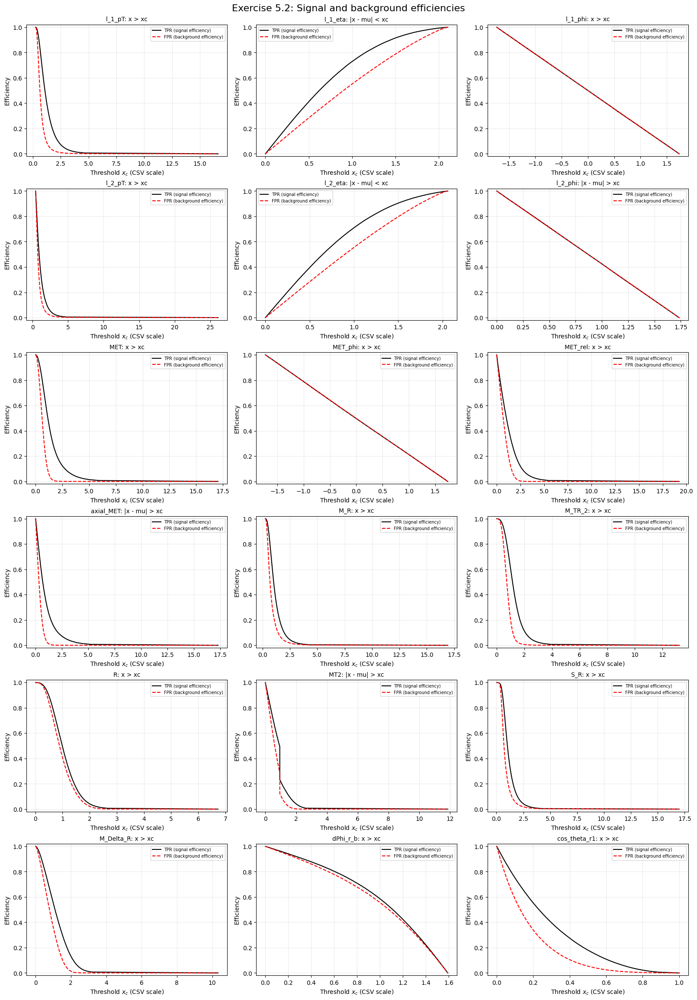

In [30]:
#5.2
fig, axes = plt.subplots(
    6, 3,
    figsize=(16, 23),
    constrained_layout=True
)

for ax, var in zip(axes.flat, observables):
    result = selection_results[var]

    ax.plot(
        result["cuts"],
        result["tpr"],
        color="black",
        label="TPR (signal efficiency)"
    )

    ax.plot(
        result["cuts"],
        result["fpr"],
        color="red",
        linestyle="--",
        label="FPR (background efficiency)"
    )

    ax.set_title(
        f"{var}: {rule_labels[result['rule']]}",
        fontsize=10
    )
    ax.set_xlabel(r"Threshold $x_c$ (CSV scale)")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

fig.suptitle(
    "Exercise 5.2: Signal and background efficiencies",
    fontsize=16
)

plt.show()

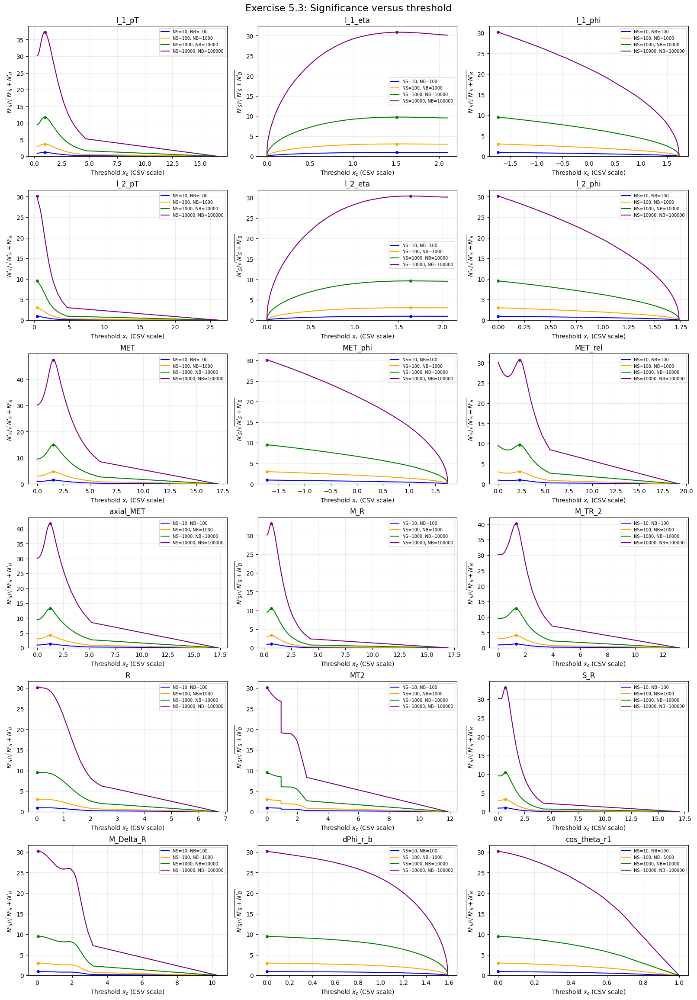

,Variable,Selection,NS,NB,Best xc,TPR,FPR,Maximum significance
0,l_1_pT,x > xc,10,100,0.9615,0.5884,0.1912,1.1767
1,l_1_pT,x > xc,100,1000,0.9615,0.5884,0.1912,3.7211
2,l_1_pT,x > xc,1000,10000,0.9615,0.5884,0.1912,11.7671
3,l_1_pT,x > xc,10000,100000,0.9615,0.5884,0.1912,37.2109
4,l_1_eta,|x - mu| < xc,10,100,1.5108,0.9179,0.7925,0.9761
5,l_1_eta,|x - mu| < xc,100,1000,1.5108,0.9179,0.7925,3.0868
6,l_1_eta,|x - mu| < xc,1000,10000,1.5108,0.9179,0.7925,9.7614
7,l_1_eta,|x - mu| < xc,10000,100000,1.5108,0.9179,0.7925,30.8681
8,l_1_phi,x > xc,10,100,-1.7348,1.0000,1.0000,0.9535
9,l_1_phi,x > xc,100,1000,-1.7348,1.0000,1.0000,3.0151


In [31]:
#5.3
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

colors = ["blue", "orange", "green", "purple"]

fig, axes = plt.subplots(
    6, 3,
    figsize=(16, 23),
    constrained_layout=True
)

best_cuts = []

for ax, var in zip(axes.flat, observables):
    result = selection_results[var]

    for (ns, nb), color in zip(scenarios, colors):
        z = significance(
            result["tpr"],
            result["fpr"],
            ns,
            nb
        )

        index = np.argmax(z)
        best_xc = result["cuts"][index]

        ax.plot(
            result["cuts"],
            z,
            color=color,
            label=f"NS={ns}, NB={nb}"
        )

        # Mark the maximum significance.
        ax.plot(
            best_xc,
            z[index],
            "o",
            color=color,
            markersize=4
        )

        best_cuts.append({
            "Variable": var,
            "Selection": rule_labels[result["rule"]],
            "NS": ns,
            "NB": nb,
            "Best xc": best_xc,
            "TPR": result["tpr"][index],
            "FPR": result["fpr"][index],
            "Maximum significance": z[index]
        })

    ax.set_title(var)
    ax.set_xlabel(r"Threshold $x_c$ (CSV scale)")
    ax.set_ylabel(r"$N'_S / \sqrt{N'_S + N'_B}$")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

fig.suptitle(
    "Exercise 5.3: Significance versus threshold",
    fontsize=16
)

plt.show()

best_cuts_df = pd.DataFrame(best_cuts)

with pd.option_context("display.max_rows", None):
    display(best_cuts_df.round(4))

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3).

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [32]:
#6.1
# Ranking variables by their best individual significance.
selected_vars = sorted(
    selection_results,
    key=lambda v: selection_results[v]["best_z"],
    reverse=True
)[:3]

chosen_cuts = {}

for var in selected_vars:
    result = selection_results[var]

    chosen_cuts[var] = {
        "rule": result["rule"],
        "mu": result["mu"],
        "xc": result["cuts"][result["best_index"]]
    }

selection_table = pd.DataFrame([
    {
        "Variable": var,
        "Selection": rule_labels[chosen_cuts[var]["rule"]],
        "xc": chosen_cuts[var]["xc"],
        "mu (band rules only)": (
            chosen_cuts[var]["mu"]
            if chosen_cuts[var]["rule"] in ["inside", "outside"]
            else np.nan
        ),
        "Individual significance (NS=10, NB=100)":
            selection_results[var]["best_z"]
    }
    for var in selected_vars
])

display(selection_table.round(4).fillna("—"))

,Variable,Selection,xc,mu (band rules only),"Individual significance (NS=10, NB=100)"
0,MET,x > xc,1.5250,—,1.4992
1,axial_MET,|x - mu| > xc,1.2552,0.0,1.3195
2,M_TR_2,x > xc,1.3054,—,1.2714


In [33]:
#6.2
def apply_cut(data, var, rule, xc, mu=0.0):
    values = data[var].to_numpy()

    if rule == "greater":
        return values > xc
    elif rule == "less":
        return values < xc
    elif rule == "outside":
        return np.abs(values - mu) > xc
    elif rule == "inside":
        return np.abs(values - mu) < xc
    else:
        raise ValueError("Unknown selection rule")


def cut_flow(signal, background, variables, cuts, ns, nb):
    signal_mask = np.ones(len(signal), dtype=bool)
    background_mask = np.ones(len(background), dtype=bool)

    rows = []

    def record_step(step):
        eps_s = signal_mask.mean()
        eps_b = background_mask.mean()

        s = ns * eps_s
        b = nb * eps_b
        z = s / np.sqrt(s + b) if s + b > 0 else 0.0

        rows.append({
            "Step": step,
            "epsilon_S": eps_s,
            "epsilon_B": eps_b,
            "N_S_prime": s,
            "N_B_prime": b,
            "Significance": z
        })

    record_step("No cuts")

    for var in variables:
        cut = cuts[var]

        signal_mask &= apply_cut(
            signal, var, cut["rule"], cut["xc"], cut["mu"]
        )
        background_mask &= apply_cut(
            background, var, cut["rule"], cut["xc"], cut["mu"]
        )

        record_step(
            f"+ {var}: {rule_labels[cut['rule']]}, "
            f"xc={cut['xc']:.4g}"
        )

    return pd.DataFrame(rows)


scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

cut_flow_tables = {}

for ns, nb in scenarios:
    print(f"\nExpected signal = {ns}, background = {nb}")

    table = cut_flow(
        df_sig, df_bkg, selected_vars, chosen_cuts, ns, nb
    )

    cut_flow_tables[(ns, nb)] = table
    display(table.round(4))


Expected signal = 10, background = 100


,Step,epsilon_S,epsilon_B,N_S_prime,N_B_prime,Significance
0,No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
1,"+ MET: x > xc, xc=1.525",0.3306,0.0156,3.3059,1.5568,1.4992
2,"+ axial_MET: |x - mu| > xc, xc=1.255",0.2209,0.0078,2.2092,0.7841,1.2769
3,"+ M_TR_2: x > xc, xc=1.305",0.1556,0.0067,1.5564,0.6663,1.0439



Expected signal = 100, background = 1000


,Step,epsilon_S,epsilon_B,N_S_prime,N_B_prime,Significance
0,No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
1,"+ MET: x > xc, xc=1.525",0.3306,0.0156,33.0585,15.5676,4.7408
2,"+ axial_MET: |x - mu| > xc, xc=1.255",0.2209,0.0078,22.0921,7.8410,4.0379
3,"+ M_TR_2: x > xc, xc=1.305",0.1556,0.0067,15.5637,6.6629,3.3012



Expected signal = 1000, background = 10000


,Step,epsilon_S,epsilon_B,N_S_prime,N_B_prime,Significance
0,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
1,"+ MET: x > xc, xc=1.525",0.3306,0.0156,330.5852,155.6758,14.9916
2,"+ axial_MET: |x - mu| > xc, xc=1.255",0.2209,0.0078,220.9208,78.4104,12.7691
3,"+ M_TR_2: x > xc, xc=1.305",0.1556,0.0067,155.6370,66.6285,10.4394



Expected signal = 10000, background = 100000


,Step,epsilon_S,epsilon_B,N_S_prime,N_B_prime,Significance
0,No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
1,"+ MET: x > xc, xc=1.525",0.3306,0.0156,3305.8518,1556.7580,47.4077
2,"+ axial_MET: |x - mu| > xc, xc=1.255",0.2209,0.0078,2209.2085,784.1037,40.3795
3,"+ M_TR_2: x > xc, xc=1.305",0.1556,0.0067,1556.3698,666.2850,33.0124


In [ ]:
#For N_S=10, N_B=100, significance rises from 0.9535 to 1.4992 after the MET cut, then drops to 1.2769 and 1.0439 after the additional cuts.

In [35]:
#6.3
corr_combined = df[selected_vars].corr()
corr_signal = df_sig[selected_vars].corr()
corr_background = df_bkg[selected_vars].corr()

pair_rows = []

# Compare each unique pair once.
for i, a in enumerate(selected_vars):
    for b in selected_vars[i + 1:]:
        rs = corr_signal.loc[a, b]
        rb = corr_background.loc[a, b]

        pair_rows.append({
            "Variable A": a,
            "Variable B": b,
            "Combined correlation": corr_combined.loc[a, b],
            "Signal correlation": rs,
            "Background correlation": rb,
            "Largest absolute within-class correlation":
                max(abs(rs), abs(rb))
        })

pair_table = pd.DataFrame(pair_rows).sort_values(
    "Largest absolute within-class correlation",
    ascending=False
)

display(pair_table.round(4))

var_a = pair_table.iloc[0]["Variable A"]
var_b = pair_table.iloc[0]["Variable B"]

print(f"Pair to investigate: {var_a} and {var_b}")

,Variable A,Variable B,Combined correlation,Signal correlation,Background correlation,Largest absolute within-class correlation
1,MET,M_TR_2,0.7197,0.6333,0.8257,0.8257
2,axial_MET,M_TR_2,-0.3175,-0.3322,-0.6928,0.6928
0,MET,axial_MET,0.1759,0.2635,-0.6543,0.6543


Pair to investigate: MET and M_TR_2


In [ ]:
#MET and M_TR_2 have a background correlation of 0.8257, supporting investigation of overlapping information.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



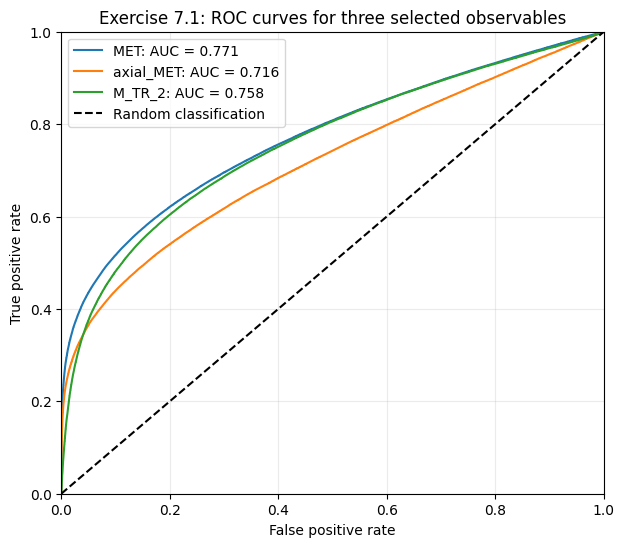

In [36]:
#7.1


def signal_score(data, var):
    result = selection_results[var]
    x = data[var].to_numpy()

    if result["rule"] == "greater":
        return x
    elif result["rule"] == "less":
        return -x
    elif result["rule"] == "outside":
        return np.abs(x - result["mu"])
    elif result["rule"] == "inside":
        return -np.abs(x - result["mu"])


def calculate_roc(signal_scores, background_scores):
    if len(signal_scores) == 0 or len(background_scores) == 0:
        raise ValueError("Both classes must contain events.")

    scores = np.concatenate([signal_scores, background_scores])
    labels = np.concatenate([
        np.ones(len(signal_scores), dtype=int),
        np.zeros(len(background_scores), dtype=int)
    ])

    # Sorting from most to least signal-like.
    order = np.argsort(-scores, kind="stable")
    scores = scores[order]
    labels = labels[order]

    # Evaluating after each group of tied scores.
    endpoints = np.r_[
        np.flatnonzero(np.diff(scores) != 0),
        len(scores) - 1
    ]

    true_positives = np.cumsum(labels)[endpoints]
    false_positives = np.cumsum(1 - labels)[endpoints]

    tpr = np.r_[0, true_positives / len(signal_scores)]
    fpr = np.r_[0, false_positives / len(background_scores)]

    # Trapezoidal integration.
    auc = np.sum(
        np.diff(fpr) * (tpr[:-1] + tpr[1:]) / 2
    )

    return fpr, tpr, auc


plt.figure(figsize=(7, 6))

for var in selected_vars:
    fpr, tpr, auc = calculate_roc(
        signal_score(df_sig, var),
        signal_score(df_bkg, var)
    )

    plt.plot(fpr, tpr, label=f"{var}: AUC = {auc:.3f}")

plt.plot([0, 1], [0, 1], "k--", label="Random classification")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Exercise 7.1: ROC curves for three selected observables")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

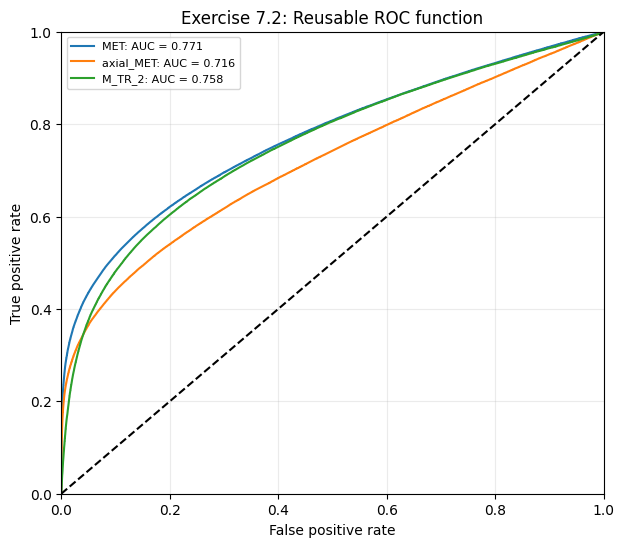

In [37]:
#7.2
def plot_roc(
    signal,
    background,
    variables,
    signal_mask=None,
    background_mask=None,
    ax=None,
    prefix=""
):
    if signal_mask is not None:
        signal = signal.loc[signal_mask]

    if background_mask is not None:
        background = background.loc[background_mask]

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))

    results = {}

    for var in variables:
        fpr, tpr, auc = calculate_roc(
            signal_score(signal, var),
            signal_score(background, var)
        )

        label = f"{prefix}{var}: AUC = {auc:.3f}"
        ax.plot(fpr, tpr, label=label)

        results[var] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": auc
        }

    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

    return ax, results



ax, roc_results = plot_roc(df_sig, df_bkg, selected_vars)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Exercise 7.2: Reusable ROC function")
plt.show()

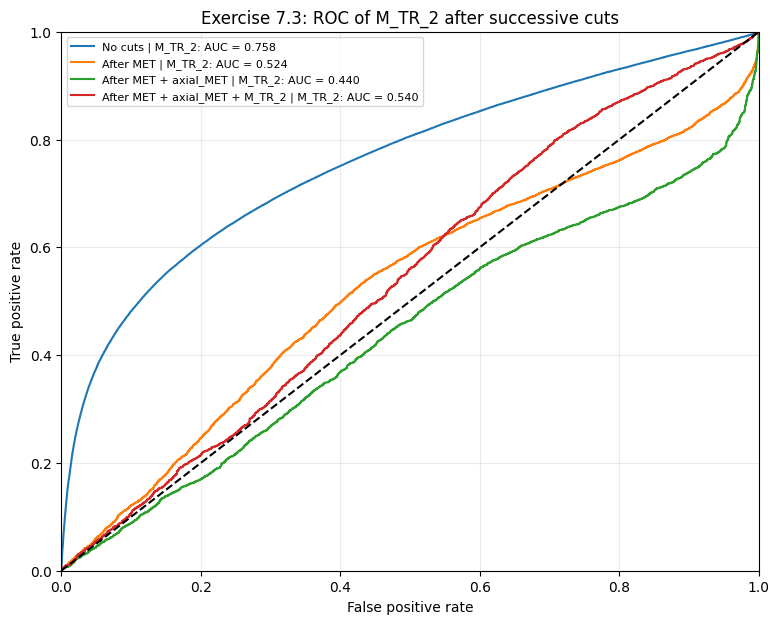

,Stage,Signal retained,Background retained,Conditional AUC
0,No cuts,1.0000,1.0000,0.7582
1,After MET,0.3306,0.0156,0.5242
2,After MET + axial_MET,0.2209,0.0078,0.4404
3,After MET + axial_MET + M_TR_2,0.1556,0.0067,0.5401


In [38]:
#7.3
probe_var = selected_vars[-1]

def plot_cut_stages(order, probe_var, ax):
    signal_mask = np.ones(len(df_sig), dtype=bool)
    background_mask = np.ones(len(df_bkg), dtype=bool)

    stage_rows = []

    for stage in range(len(order) + 1):
        if stage > 0:
            var = order[stage - 1]
            cut = chosen_cuts[var]

            signal_mask &= apply_cut(
                df_sig, var,
                cut["rule"], cut["xc"], cut["mu"]
            )
            background_mask &= apply_cut(
                df_bkg, var,
                cut["rule"], cut["xc"], cut["mu"]
            )

        stage_label = (
            "No cuts"
            if stage == 0
            else "After " + " + ".join(order[:stage])
        )

        if signal_mask.sum() == 0 or background_mask.sum() == 0:
            print(f"{stage_label}: ROC undefined; one class is empty.")
            break

        _, results = plot_roc(
            df_sig,
            df_bkg,
            [probe_var],
            signal_mask=signal_mask,
            background_mask=background_mask,
            ax=ax,
            prefix=stage_label + " | "
        )

        stage_rows.append({
            "Stage": stage_label,
            "Signal retained": signal_mask.mean(),
            "Background retained": background_mask.mean(),
            "Conditional AUC": results[probe_var]["auc"]
        })

    return pd.DataFrame(stage_rows), signal_mask, background_mask


fig, ax = plt.subplots(figsize=(9, 7))

stage_table, final_signal_mask, final_background_mask = (
    plot_cut_stages(selected_vars, probe_var, ax)
)

ax.plot([0, 1], [0, 1], "k--")
ax.set_title(f"Exercise 7.3: ROC of {probe_var} after successive cuts")
plt.show()

display(stage_table.round(4))

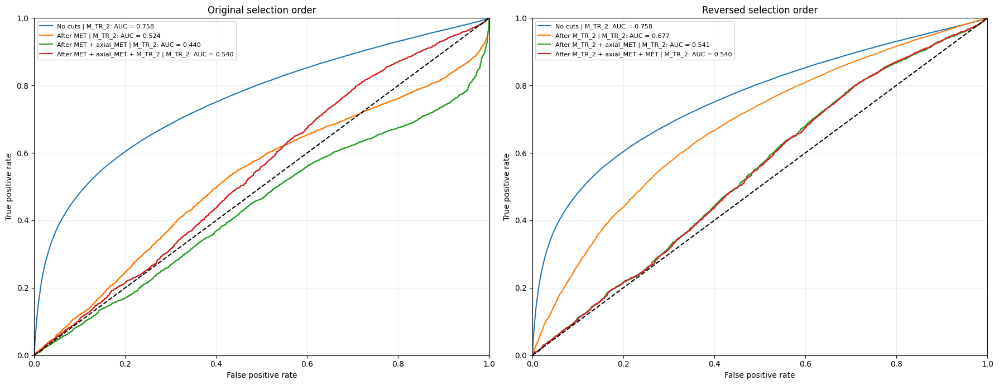

Original order: MET → axial_MET → M_TR_2


,Stage,Signal retained,Background retained,Conditional AUC
0,No cuts,1.0000,1.0000,0.7582
1,After MET,0.3306,0.0156,0.5242
2,After MET + axial_MET,0.2209,0.0078,0.4404
3,After MET + axial_MET + M_TR_2,0.1556,0.0067,0.5401


Reversed order: M_TR_2 → axial_MET → MET


,Stage,Signal retained,Background retained,Conditional AUC
0,No cuts,1.0000,1.0000,0.7582
1,After M_TR_2,0.3920,0.0559,0.6771
2,After M_TR_2 + axial_MET,0.1590,0.0069,0.5411
3,After M_TR_2 + axial_MET + MET,0.1556,0.0067,0.5401


Identical final signal selections: True
Identical final background selections: True


In [39]:
#7.4
forward_order = list(selected_vars)
reverse_order = list(reversed(selected_vars))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

forward_table, forward_sig, forward_bkg = plot_cut_stages(
    forward_order, probe_var, axes[0]
)

reverse_table, reverse_sig, reverse_bkg = plot_cut_stages(
    reverse_order, probe_var, axes[1]
)

for ax, title in zip(
    axes,
    ["Original selection order", "Reversed selection order"]
):
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(title)

plt.tight_layout()
plt.show()

print("Original order:", " → ".join(forward_order))
display(forward_table.round(4))

print("Reversed order:", " → ".join(reverse_order))
display(reverse_table.round(4))

print(
    "Identical final signal selections:",
    np.array_equal(forward_sig, reverse_sig)
)

print(
    "Identical final background selections:",
    np.array_equal(forward_bkg, reverse_bkg)
)

In [ ]:
#Both final-selection checks return True, correctly showing that reversing fixed cuts leaves the final selected events unchanged.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$.

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5?

In [40]:
#8.1
features = VarNames[1:]

X_bkg = df_bkg[features].to_numpy(dtype=float)
X_sig = df_sig[features].to_numpy(dtype=float)

# Class means.
m1 = X_bkg.mean(axis=0)
m2 = X_sig.mean(axis=0)

mean_difference = m2 - m1

# Between-class scatter matrix.
S_B = np.outer(mean_difference, mean_difference)

# Within-class scatter matrix.
centered_bkg = X_bkg - m1
centered_sig = X_sig - m2

S_W = (
    centered_bkg.T @ centered_bkg
    + centered_sig.T @ centered_sig
)

print("Between-class matrix S_B:")
display(pd.DataFrame(
    S_B, index=features, columns=features
).round(4))

print("Within-class matrix S_W:")
display(pd.DataFrame(
    S_W, index=features, columns=features
).round(4))

Between-class matrix S_B:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.2880,0.0005,0.0005,0.1381,0.0015,0.0004,0.4135,-0.0006,0.2711,0.0855,0.1823,0.2666,0.0553,0.0738,0.1742,0.1841,0.0154,0.0566
l_1_eta,0.0005,0.0000,0.0000,0.0002,0.0000,0.0000,0.0007,-0.0000,0.0004,0.0001,0.0003,0.0004,0.0001,0.0001,0.0003,0.0003,0.0000,0.0001
l_1_phi,0.0005,0.0000,0.0000,0.0002,0.0000,0.0000,0.0007,-0.0000,0.0004,0.0001,0.0003,0.0004,0.0001,0.0001,0.0003,0.0003,0.0000,0.0001
l_2_pT,0.1381,0.0002,0.0002,0.0663,0.0007,0.0002,0.1984,-0.0003,0.1301,0.0410,0.0875,0.1279,0.0265,0.0354,0.0836,0.0883,0.0074,0.0272
l_2_eta,0.0015,0.0000,0.0000,0.0007,0.0000,0.0000,0.0022,-0.0000,0.0015,0.0005,0.0010,0.0014,0.0003,0.0004,0.0009,0.0010,0.0001,0.0003
l_2_phi,0.0004,0.0000,0.0000,0.0002,0.0000,0.0000,0.0005,-0.0000,0.0003,0.0001,0.0002,0.0003,0.0001,0.0001,0.0002,0.0002,0.0000,0.0001
MET,0.4135,0.0007,0.0007,0.1984,0.0022,0.0005,0.5936,-0.0009,0.3893,0.1227,0.2618,0.3827,0.0794,0.1059,0.2502,0.2644,0.0221,0.0813
MET_phi,-0.0006,-0.0000,-0.0000,-0.0003,-0.0000,-0.0000,-0.0009,0.0000,-0.0006,-0.0002,-0.0004,-0.0006,-0.0001,-0.0002,-0.0004,-0.0004,-0.0000,-0.0001
MET_rel,0.2711,0.0004,0.0004,0.1301,0.0015,0.0003,0.3893,-0.0006,0.2553,0.0805,0.1717,0.2510,0.0521,0.0695,0.1641,0.1734,0.0145,0.0533
axial_MET,0.0855,0.0001,0.0001,0.0410,0.0005,0.0001,0.1227,-0.0002,0.0805,0.0254,0.0541,0.0791,0.0164,0.0219,0.0517,0.0546,0.0046,0.0168


Within-class matrix S_W:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,197992.3142,-255.3066,-19.7201,135369.1269,-365.6708,323.2210,62890.4849,-389.3275,15103.4849,-15475.8396,159581.4884,110521.3976,-36718.8498,-15358.6322,149663.0616,26013.4287,-25386.9596,4051.8756
l_1_eta,-255.3066,502149.6230,-428.9070,-108.7830,204155.7338,-521.0766,-1155.2830,-294.3576,-738.9243,-571.3530,-312.9839,-387.1933,139.7050,198.9643,-336.4749,-530.1589,-373.2121,149.6129
l_1_phi,-19.7201,-428.9070,501985.5840,628.6395,125.0467,-133404.8960,299.8630,-92401.6755,298.4639,-953.5664,494.7892,380.6748,89.6491,515.2765,696.7688,413.5132,494.0474,118.1375
l_2_pT,135369.1269,-108.7830,628.6395,204517.4547,-379.5376,56.1397,15102.8953,-742.9710,-16413.9894,20575.1196,151858.4668,65595.9954,-52970.0971,-38836.8331,150592.9868,-8106.9238,-2834.7812,-17327.4784
l_2_eta,-365.6708,204155.7338,125.0467,-379.5376,503130.1990,220.5505,-83.7780,-160.8016,362.0672,-434.9877,-424.9317,-167.5986,123.5690,650.4424,-455.0146,212.9348,-163.6672,110.5600
l_2_phi,323.2210,-521.0766,-133404.8960,56.1397,220.5505,501898.1004,-217.2387,-17717.0157,680.7250,-913.7381,351.1819,212.3923,266.8412,1117.9285,425.7199,634.2396,-123.0356,9.5831
MET,62890.4849,-1155.2830,299.8630,15102.8953,-83.7780,-217.2387,307430.1902,-1282.5940,224914.0714,61744.9175,39762.7766,135086.6792,84095.4273,64241.7739,51715.1882,124755.3374,70094.9680,26452.9776
MET_phi,-389.3275,-294.3576,-92401.6755,-742.9710,-160.8016,-17717.0157,-1282.5940,501655.3981,-2373.1877,-197.4403,-691.5358,-527.3469,-99.5826,62.1826,-805.5545,-234.3973,-850.3005,75.2430
MET_rel,15103.4849,-738.9243,298.4639,-16413.9894,362.0672,680.7250,224914.0714,-2373.1877,363552.9121,-69914.8510,531.0012,119840.3214,117945.3252,195765.2267,20791.9386,185851.2662,71418.9090,21040.0960
axial_MET,-15475.8396,-571.3530,-953.5664,20575.1196,-434.9877,-913.7381,61744.9175,-197.4403,-69914.8510,499537.1937,1849.6798,-102328.8973,-92488.1249,-233217.1809,-27110.8960,-123320.0907,-13123.9563,-28953.7003


,Observable,Fisher coefficient
0,l_1_pT,2.268330e-06
1,l_1_eta,5.636884e-09
2,l_1_phi,2.104239e-09
3,l_2_pT,9.955830e-07
4,l_2_eta,3.484522e-09
5,l_2_phi,2.707626e-09
6,MET,1.651854e-06
7,MET_phi,2.742418e-09
8,MET_rel,1.397233e-07
9,axial_MET,2.642057e-07


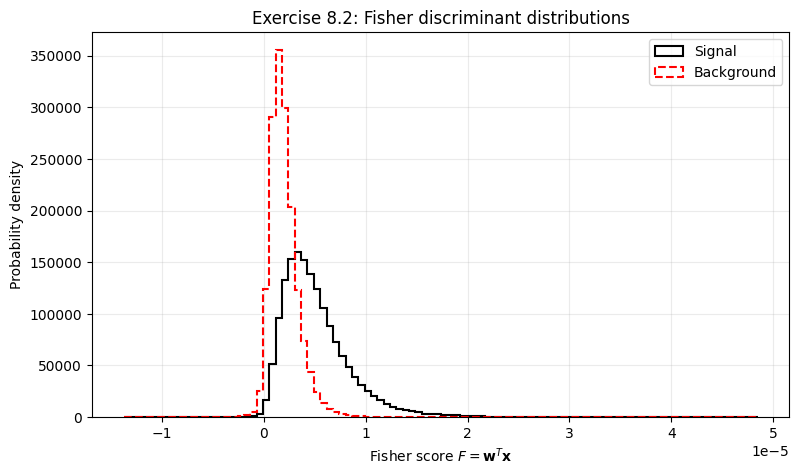

Mean signal score:     5.12925e-06
Mean background score: 2.02579e-06


In [41]:
#8.2

w = np.linalg.solve(S_W, mean_difference)

display(pd.DataFrame({
    "Observable": features,
    "Fisher coefficient": w
}))

# One Fisher score for each event.
F_sig = X_sig @ w
F_bkg = X_bkg @ w

# Shared bins spanning both classes.
bins = np.histogram_bin_edges(
    np.concatenate([F_sig, F_bkg]),
    bins=100
)

plt.figure(figsize=(9, 5))

plt.hist(
    F_sig,
    bins=bins,
    density=True,
    histtype="step",
    color="black",
    linewidth=1.5,
    label="Signal"
)

plt.hist(
    F_bkg,
    bins=bins,
    density=True,
    histtype="step",
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Background"
)

plt.xlabel(r"Fisher score $F = \mathbf{w}^{T}\mathbf{x}$")
plt.ylabel("Probability density")
plt.title("Exercise 8.2: Fisher discriminant distributions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Mean signal score:     {F_sig.mean():.6g}")
print(f"Mean background score: {F_bkg.mean():.6g}")

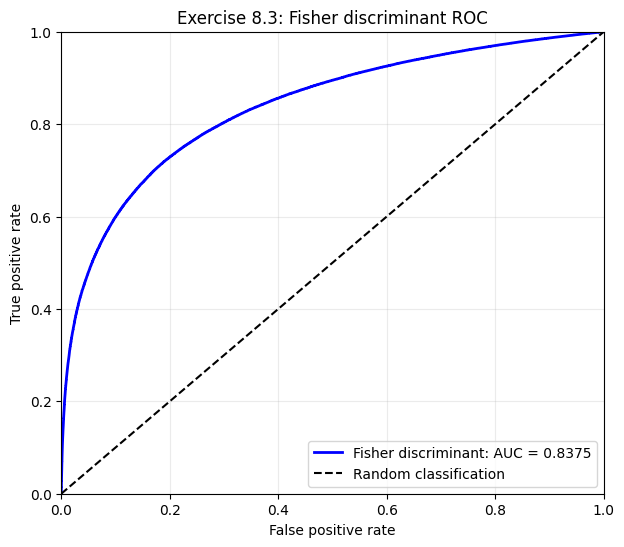

In [42]:
#8.3
fpr_fisher, tpr_fisher, auc_fisher = calculate_roc(
    F_sig, F_bkg
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_fisher,
    tpr_fisher,
    color="blue",
    linewidth=2,
    label=f"Fisher discriminant: AUC = {auc_fisher:.4f}"
)

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classification"
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Exercise 8.3: Fisher discriminant ROC")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [43]:
#8.4
# Combining scores and class labels.
scores = np.concatenate([F_sig, F_bkg])
labels = np.concatenate([
    np.ones(len(F_sig), dtype=int),
    np.zeros(len(F_bkg), dtype=int)
])

# Sorting from highest score to lowest.
order = np.argsort(-scores, kind="stable")
sorted_scores = scores[order]
sorted_labels = labels[order]

# Evaluating after each group of equal scores.
endpoints = np.r_[
    np.flatnonzero(np.diff(sorted_scores) != 0),
    len(sorted_scores) - 1
]

thresholds = sorted_scores[endpoints]

epsilon_s = (
    np.cumsum(sorted_labels)[endpoints] / len(F_sig)
)

epsilon_b = (
    np.cumsum(1 - sorted_labels)[endpoints] / len(F_bkg)
)

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

fisher_results = []

for ns, nb in scenarios:
    z = significance(epsilon_s, epsilon_b, ns, nb)
    best_index = np.argmax(z)

    fisher_results.append({
        "NS": ns,
        "NB": nb,
        "Best Fisher threshold": thresholds[best_index],
        "Signal efficiency": epsilon_s[best_index],
        "Background efficiency": epsilon_b[best_index],
        "Expected signal after cut":
            ns * epsilon_s[best_index],
        "Expected background after cut":
            nb * epsilon_b[best_index],
        "Maximum significance": z[best_index]
    })

fisher_results_df = pd.DataFrame(fisher_results)

display(
    fisher_results_df.style.format({
        "Best Fisher threshold": "{:.6g}",
        "Signal efficiency": "{:.4f}",
        "Background efficiency": "{:.4f}",
        "Expected signal after cut": "{:.4f}",
        "Expected background after cut": "{:.4f}",
        "Maximum significance": "{:.4f}"
    })
)

,NS,NB,Best Fisher threshold,Signal efficiency,Background efficiency,Expected signal after cut,Expected background after cut,Maximum significance
0,10,100,4.49761e-06,0.4916,0.0537,4.9163,5.3742,1.5326
1,100,1000,4.49761e-06,0.4916,0.0537,49.1631,53.7423,4.8464
2,1000,10000,4.49761e-06,0.4916,0.0537,491.6312,537.4231,15.3257
3,10000,100000,4.49761e-06,0.4916,0.0537,4916.3122,5374.2313,48.4641
